# №6 зертханалық жұмыс
## Модельдердің шамадан тыс және жеткіліксіз үйренуін зерттеу. Регуляризация мен теңгерімсіз деректермен жұмыс әдістерін қолдану.

Толық синтетикалық екі тәжірибе. Регрессия: alpha таңдау тек train ішіндегі ортақ бес бүктемелі CV бойынша. Жіктеу: бекітілген модельдер, class_weight және .5 шегі, test бойынша таңдаусыз. Барлық seed, торлар және FP+5FN бағасы алдын ала берілген. Таза іске қосу артефактілерді `lab06_artifacts` ішінде сақтайды. Дереккөздер: авторлық S06/S12 және силлабустағы дәл атау. Бастапқы авторлық тәжірибе бейімделген, нәтижелер жаңа генераторларға қатысты.

**Мақсат:** тәуелсіз қорытынды бөлікті сақтап, коэффициенттер регуляризациясын класс салмағын өзгертуден ажырату, қателерді, сиректікті және ықтималдық бағаларын салыстыру.

### 1-қадам Орта және келісімдер
Нөл емес коэффициент: стандартталған салмақ модулі 1e-8 шамасынан үлкен. Оң класс 1; шешім `p>=.5`. Оң шешімдерсіз Precision нөл болып жазылады. AP average_precision_score білдіреді, Brier бинарлық 0–1 шкаласын қолданады. Қайта іріктеу үшін бөлек пакеттер қажет емес.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression, make_classification
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, average_precision_score, roc_auc_score, brier_score_loss)
from sklearn.utils.class_weight import compute_class_weight

ROOT = Path.cwd() / "lab06_artifacts"
FIGURES, DATASETS = ROOT / "figures", ROOT / "datasets"
FIGURES.mkdir(parents=True, exist_ok=True)
DATASETS.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"
TOLERANCE = 1e-8



from IPython.display import display, Image
from importlib.metadata import version
for package in ("numpy", "pandas", "scikit-learn", "matplotlib"):
    print(package, version(package))


numpy 2.5.4
pandas 3.0.1
scikit-learn 1.9.1
matplotlib 3.11.2


### 2 және 6-қадамдар Деректер және тәуелсіз бөліктер
Регрессия: 240×30, 5 ақпаратты белгі, noise=20, seed=2026; seed=2026 бар 80/20 split кейін 192/48. Жіктеу: 1200×10, 5 ақпаратты және 2 артық белгі, weights=[.95,.05], class_sep=1.5, flip_y=.01, seed=2026; стратификацияланған бөлу 960/240. Әзірге өлшемдер мен train сандары зерттеледі. Сақталған CSV ішіндегі target/split өрістері қызметтік, белгі ретінде берілмейді.

In [2]:
def make_regression_split():
    raw, target, truth = make_regression(
        n_samples=240, n_features=30, n_informative=5,
        noise=20, random_state=2026, coef=True)
    X = pd.DataFrame(raw, columns=[f"x{j}" for j in range(30)])
    y = pd.Series(target, name="target")
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=.2, random_state=2026)
    return {"X": X, "y": y, "truth": truth,
            "train": (Xa, ya), "test": (Xb, yb)}


def make_rare_split():
    raw, target = make_classification(
        n_samples=1200, n_features=10, n_informative=5, n_redundant=2,
        weights=[.95, .05], class_sep=1.5, flip_y=.01, random_state=2026)
    X = pd.DataFrame(raw, columns=[f"x{j}" for j in range(10)])
    y = pd.Series(target, name="target")
    Xa, Xb, ya, yb = train_test_split(
        X, y, test_size=.2, stratify=y, random_state=2026)
    return {"X": X, "y": y, "train": (Xa, ya), "test": (Xb, yb)}



regression_split = make_regression_split()
rare_split = make_rare_split()
print("Регрессия train/test:", [len(regression_split[s][1]) for s in ["train", "test"]])
print("Жіктеу train/test:", [len(rare_split[s][1]) for s in ["train", "test"]])
print("Тек train кластары:", np.bincount(rare_split["train"][1], minlength=2))


Регрессия train/test: [192, 48]
Жіктеу train/test: [960, 240]
Тек train кластары: [910  50]


### 3–4-қадамдар GridSearchCV ішіндегі толық Pipeline
Shuffle=True, seed=2027 бар бес KFold бүктемесінің бір тізімі Ridge және Lasso үшін қолданылады. Торлар: Ridge [.01,.1,1,10,100], Lasso [.01,.1,1,10]. Критерий — бес тексеру бөлігінің орташа RMSE шамасы. Толық Pipeline әр бүктеменің ішінде оқытылады, refit=True үздік fit әрекетін 192 train жолында қайталайды. DummyMean/OLS сол train бөлігінде оқытылады. Тәуелсіз жауаптар әзірге қолданылмайды.

In [3]:
def fit_regression(split):
    Xa, ya = split["train"]
    cv = list(KFold(n_splits=5, shuffle=True, random_state=2027).split(Xa))
    grids = {"Ridge": (Ridge(), [.01, .1, 1, 10, 100]),
             "Lasso": (Lasso(max_iter=10000), [.01, .1, 1, 10])}
    models = {"DummyMean": DummyRegressor(strategy="mean"),
              "OLS": Pipeline([("scale", StandardScaler()),
                               ("model", LinearRegression())])}
    for model in models.values():
        model.fit(Xa, ya)
    searches, paths = {}, {}
    for name, (estimator, alphas) in grids.items():
        pipe = Pipeline([("scale", StandardScaler()), ("model", estimator)])
        search = GridSearchCV(
            pipe, {"model__alpha": alphas}, cv=cv, refit=True, n_jobs=1,
            scoring="neg_root_mean_squared_error", error_score="raise")
        search.fit(Xa, ya)
        searches[name], models[name] = search, search.best_estimator_
        scores = search.cv_results_
        paths[name] = [{
            "alpha": float(alpha),
            "mean_CV_RMSE": float(-scores["mean_test_score"][j]),
            "fold_RMSE": [float(-scores[f"split{k}_test_score"][j])
                          for k in range(5)],
        } for j, alpha in enumerate(alphas)]
        print(name, "CV бойынша alpha:", search.best_params_["model__alpha"],
              "орташа CV RMSE:", -search.best_score_)
    return {"models": models, "searches": searches, "paths": paths,
            "CV_indices": cv}



regression_state = fit_regression(regression_split)


Ridge CV бойынша alpha: 0.1 орташа CV RMSE: 20.489765028027527


Lasso CV бойынша alpha: 1 орташа CV RMSE: 19.947052444096947


**Сіздің жауабыңыз.** Ridge alpha=.1 неліктен нормалауы бойынша Lasso alpha=.1 мәніне тең емес? Ішкі бүктемелерде және refit кезінде масштабтаушыға қанша жол қолжетімді? Бес RMSE орташалауы біріктірілген бүктемеден тыс болжамдардың RMSE шамасынан несімен өзгеше?

_Өз түсіндірмеңізді жазыңыз._

### 5-қадам Регрессияның бір қорытынды test бөлігі
Бекіткеннен кейін MAE/RMSE/R² және модулі>1e-8 салмақтар санын аламыз. Сурет test бойынша баптауды емес, тек CV қателерін көрсетеді. Тиісті оқыту өлшемі үшін Ridge alpha=nλ, Lasso alpha=λ.

Регрессияның бір test бөлігі, 48 жол:
     model        MAE       RMSE        R2  practical_nonzero
DummyMean 100.473656 121.165310 -0.000265                NaN
      OLS  15.063888  18.549907  0.976555               30.0
    Ridge  15.066199  18.558975  0.976533               30.0
    Lasso  14.584607  17.840151  0.978315               17.0


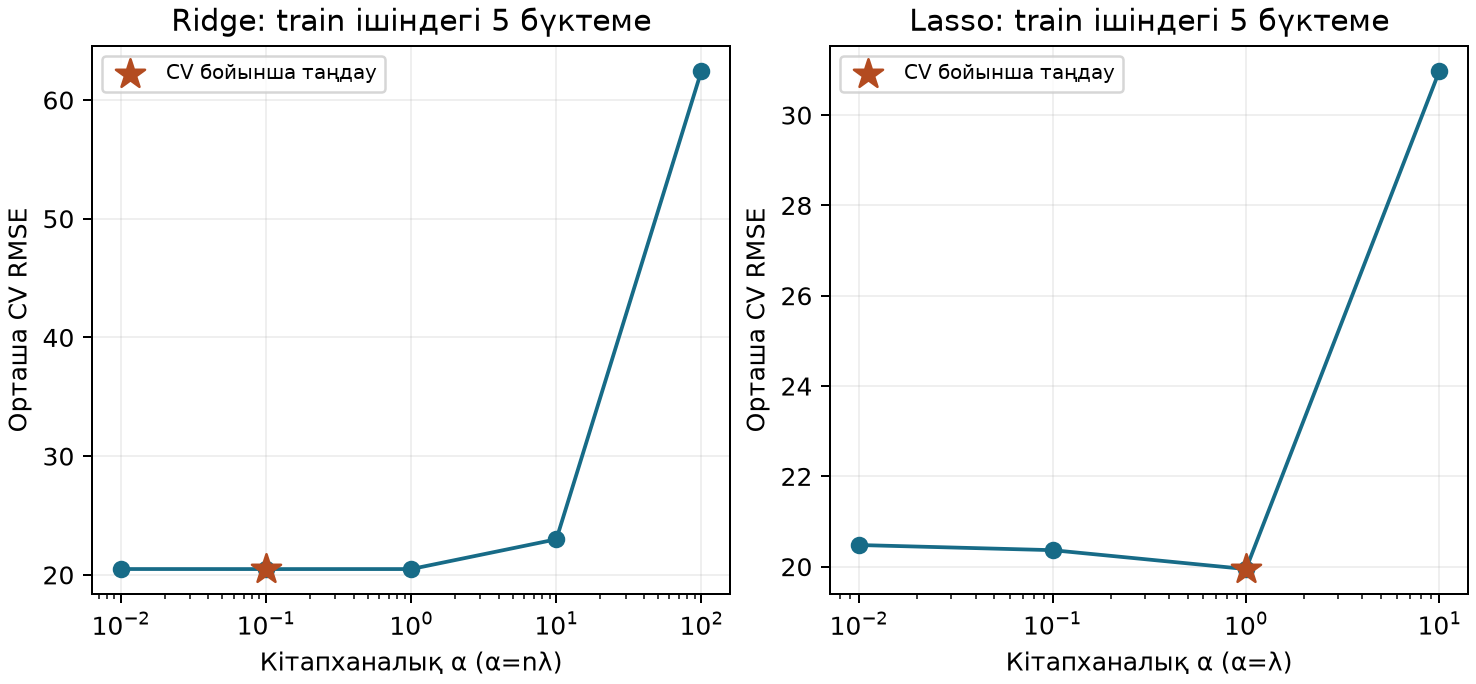

In [4]:
def evaluate_regression(split, state):
    Xa, ya = split["train"]
    Xb, yb = split["test"]
    rows, coefficients = [], {}
    for name, model in state["models"].items():
        prediction = model.predict(Xb)
        coef = (model.named_steps["model"].coef_
                if name != "DummyMean" else np.array([]))
        coefficients[name] = coef.tolist()
        rows.append({"model": name,
                     "MAE": mean_absolute_error(yb, prediction),
                     "RMSE": root_mean_squared_error(yb, prediction),
                     "R2": r2_score(yb, prediction),
                     "practical_nonzero": int(np.count_nonzero(
                         np.abs(coef) > TOLERANCE)) if coef.size else None})
    print("Регрессияның бір test бөлігі, 48 жол:\n",
          pd.DataFrame(rows).to_string(index=False))
    fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.8), layout="constrained")
    for ax, name, note in zip(axes, ["Ridge", "Lasso"], ["α=nλ", "α=λ"]):
        path = state["paths"][name]
        ax.semilogx([r["alpha"] for r in path],
                    [r["mean_CV_RMSE"] for r in path], "o-", color="#176B87")
        search = state["searches"][name]
        ax.scatter([search.best_params_["model__alpha"]],
                   [-search.best_score_], marker="*", s=150,
                   color="#B34B20", zorder=3, label="CV бойынша таңдау")
        ax.set(xlabel=f"Кітапханалық α ({note})", ylabel="Орташа CV RMSE",
               title=f"{name}: train ішіндегі 5 бүктеме")
        ax.grid(alpha=.2); ax.legend(fontsize=8)
    fig.savefig(FIGURES / "ch06_05_regularization.png", dpi=180)
    plt.close(fig)
    service = pd.Series("test", index=split["X"].index)
    service.loc[Xa.index] = "train"
    split["X"].assign(target=split["y"], split=service).to_csv(
        DATASETS / "synthetic_regularization_regression.csv", index=False)
    return {"synthetic": True, "rows": 240, "features": 30,
            "n_informative": 5, "noise": 20, "sizes": [len(ya), len(yb)],
            "generator_seed": 2026, "split_seed": 2026,
            "CV_seed": 2027, "CV_folds": 5,
            "common_CV_splits": True, "Pipeline_inside_GridSearchCV": True,
            "CV_paths": state["paths"],
            "selected_alpha": {name: float(s.best_params_["model__alpha"])
                               for name, s in state["searches"].items()},
            "test_rows": rows, "coefficient_tolerance": TOLERANCE,
            "standardized_coefficients": coefficients,
            "true_coefficients_raw_units": split["truth"].tolist(),
            "train_indices": Xa.index.tolist(), "test_indices": Xb.index.tolist(),
            "splits_disjoint": not bool(set(Xa.index) & set(Xb.index)),
            "final_scaler_fit_rows": {
                name: int(m.named_steps["scale"].n_samples_seen_)
                for name, m in state["models"].items() if name != "DummyMean"}}



regression_result = evaluate_regression(regression_split, regression_state)
display(Image(filename=str(FIGURES / "ch06_05_regularization.png")))


Тексерілген тәжірибеде Ridge alpha=.1 (CV RMSE 20.489765), Lasso alpha=1 (19.947052) таңдалған. Test RMSE: Dummy — 121.165310; OLS — 18.549907; Ridge — 18.558975; Lasso — 17.840151. Генераторда 5 ақпаратты белгі болғанымен, OLS/Ridge/Lasso нөл емес салмақтары 30/30/17. Жиынтық дәл қалпына келтірілді деуге болмайды. Ridge кіші айыптарының жақындығы жалғыз сенімді оңтайлы мән бар екенін дәлелдемейді.

**Сіздің жауабыңыз.** Dummy теріс R² мәнін және болжам критерийінің шынайы белгілерді қалпына келтіруден айырмасын түсіндіріңіз.

_Өз түсіндірмеңізді жазыңыз._

### 7-қадам Класс салмақтары тек train бойынша
Екі Pipeline(StandardScaler,LogisticRegression(C=1,max_iter=2000)), class_weight=None немесе balanced; DummyPrior. n/(2n_c) формуласы тек train қолданады. .5 шегі алдын ала бекітілген. Balanced — мақсаттың өзгеруі, ол тікелей FN=5 бағасымен берілмейді.

In [5]:
def fit_rare(split):
    Xa, ya = split["train"]
    models = {"DummyPrior": DummyClassifier(strategy="prior")}
    for name, weight in [("Unweighted", None), ("Balanced", "balanced")]:
        models[name] = Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(C=1, max_iter=2000, class_weight=weight))])
    for model in models.values():
        model.fit(Xa, ya)
    counts = np.bincount(ya, minlength=2)
    weights = len(ya) / (2 * counts)
    np.testing.assert_allclose(weights, compute_class_weight(
        class_weight="balanced", classes=np.array([0, 1]), y=ya))
    print("Train сандары:", counts, "balanced салмақтары:", weights)
    return {"models": models, "train_counts": counts, "class_weights": weights}



rare_state = fit_rare(rare_split)


Train сандары: [910  50] balanced салмақтары: [0.52747253 9.6       ]


Train сандары: 910/50; салмақтар 960/(2·910)≈.527472527 және 960/(2·50)=9.6. Әр кластың жиынтық салмағы 480. 18.2 салмақтар қатынасы 5 бағалар қатынасынан өзгеше. Масштабтау кәдімгі салмақсыз, салмақтар тек регрессияға беріледі.

**Сіздің жауабыңыз.** Test неге теңгерілмеуі тиіс және balanced неге ең аз FP+5FN шамасына уәде бермейді?

_Есептеу мен түсіндірмені жазыңыз._

### 8–9-қадамдар Жіктеудің бір test бөлігі және график
TN/FP/FN/TP матрицасы; P/R/F1/Accuracy — белгілер бойынша, AP/AUC/Brier — ықтималдықтар бойынша. Оң жақтағы сурет бір жолдағы екі рәсім бағаларын салыстырады. Диагональ калибрлеуді емес, модель бағаларының теңдігін білдіреді. Test үлестері сақталады, шек өзгермейді.

Сирек оқиғаның бір test бөлігі, шек .5:


      model  TN  FP  FN  TP  Precision   Recall       F1  Accuracy       AP  ROC_AUC    Brier  cost_FP1_FN5
DummyPrior 228   0  12   0   0.000000 0.000000 0.000000  0.950000 0.050000 0.500000 0.047504            60
Unweighted 228   0  11   1   1.000000 0.083333 0.153846  0.954167 0.534496 0.797880 0.033884            55
  Balanced 180  48   1  11   0.186441 0.916667 0.309859  0.795833 0.222479 0.861111 0.173569            53


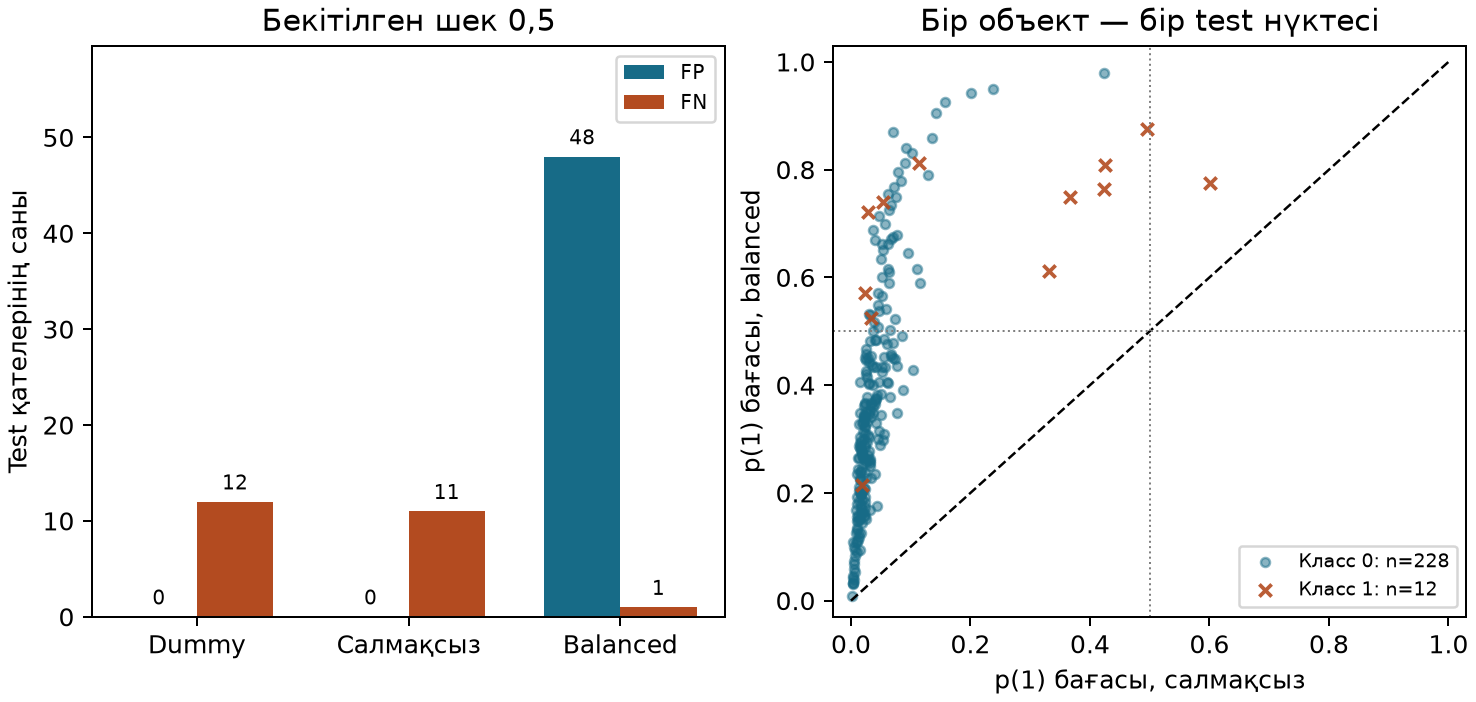

In [6]:
def evaluate_rare(split, state):
    Xa, ya = split["train"]
    Xb, yb = split["test"]
    rows, probabilities = [], {}
    for name, model in state["models"].items():
        column = int(np.flatnonzero(model.classes_ == 1)[0])
        probability = model.predict_proba(Xb)[:, column]
        probabilities[name] = probability
        prediction = (probability >= .5).astype(int)
        tn, fp, fn, tp = confusion_matrix(yb, prediction, labels=[0, 1]).ravel()
        rows.append({"model": name, "TN": int(tn), "FP": int(fp),
                     "FN": int(fn), "TP": int(tp),
                     "Precision": precision_score(yb, prediction, zero_division=0),
                     "Recall": recall_score(yb, prediction, zero_division=0),
                     "F1": f1_score(yb, prediction, zero_division=0),
                     "Accuracy": accuracy_score(yb, prediction),
                     "AP": average_precision_score(yb, probability),
                     "ROC_AUC": roc_auc_score(yb, probability),
                     "Brier": brier_score_loss(yb, probability, pos_label=1,
                                               scale_by_half=True),
                     "cost_FP1_FN5": int(fp + 5 * fn)})
    print("Сирек оқиғаның бір test бөлігі, шек .5:\n",
          pd.DataFrame(rows).to_string(index=False))
    fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.9), layout="constrained")
    x = np.arange(3)
    for key, offset, color in [("FP", -.18, "#176B87"),
                                ("FN", .18, "#B34B20")]:
        bars = axes[0].bar(x + offset, [r[key] for r in rows],
                           width=.36, label=key, color=color)
        axes[0].bar_label(bars, padding=3, fontsize=8)
    axes[0].set(xticks=x, xticklabels=["Dummy", "Салмақсыз", "Balanced"],
                ylabel="Test қателерінің саны", title="Бекітілген шек 0,5")
    axes[0].set_ylim(0, max(max(r["FP"], r["FN"]) for r in rows) * 1.22 + 1)
    axes[0].legend(fontsize=8)
    for label, color, marker in [(0, "#176B87", "o"), (1, "#B34B20", "x")]:
        mask = yb.to_numpy() == label
        axes[1].scatter(probabilities["Unweighted"][mask],
                        probabilities["Balanced"][mask], s=24 if label else 13,
                        alpha=.9 if label else .5, color=color, marker=marker,
                        label=f"Класс {label}: n={mask.sum()}")
    axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[1].axhline(.5, color="grey", linewidth=.8, linestyle=":")
    axes[1].axvline(.5, color="grey", linewidth=.8, linestyle=":")
    axes[1].set(xlabel="p(1) бағасы, салмақсыз", ylabel="p(1) бағасы, balanced",
                title="Бір объект — бір test нүктесі", xlim=(-.03, 1.03),
                ylim=(-.03, 1.03))
    axes[1].legend(fontsize=7.5, loc="lower right")
    fig.savefig(FIGURES / "ch06_06_rare_events.png", dpi=180)
    plt.close(fig)
    service = pd.Series("test", index=split["X"].index)
    service.loc[Xa.index] = "train"
    split["X"].assign(target=split["y"], split=service).to_csv(
        DATASETS / "synthetic_rare_events.csv", index=False)
    return {"synthetic": True, "rows": 1200, "features": 10,
            "n_informative": 5, "n_redundant": 2, "nominal_weights": [.95, .05],
            "class_sep": 1.5, "flip_y": .01, "seed": 2026,
            "sizes": [len(ya), len(yb)],
            "train_counts": state["train_counts"].tolist(),
            "test_counts": np.bincount(yb, minlength=2).tolist(),
            "balanced_train_weights": state["class_weights"].tolist(),
            "threshold": .5, "test_rows": rows,
            "test_probabilities": {k: p.tolist() for k, p in probabilities.items()},
            "test_y": yb.tolist(),
            "train_indices": Xa.index.tolist(), "test_indices": Xb.index.tolist(),
            "splits_disjoint": not bool(set(Xa.index) & set(Xb.index)),
            "class_weight_origin": "960 train targets only",
            "test_rebalanced": False, "resampling_performed": False,
            "final_scaler_fit_rows": {
                name: int(m.named_steps["scale"].n_samples_seen_)
                for name, m in state["models"].items() if name != "DummyPrior"}}



rare_result = evaluate_rare(rare_split, rare_state)
display(Image(filename=str(FIGURES / "ch06_06_rare_events.png")))


Test ішінде 228/12 объект бар. Салмақсыз модель: FP=0, FN=11, TP=1, құн 55. Balanced: FP=48, FN=1, TP=11, құн 53. Он өткізіп алудан үнемделген 50 бірлік 48 жалған дабылмен ішінара өтелген. AP .534496→.222479 азаяды, ROC-AUC .797880→.861111 өседі, Brier .033884→.173569 нашарлайды. Dummy Accuracy=.95 және құн 60 мәндеріне ие.

**Сіздің жауабыңыз.** Recall үлкен өсімі неге құнның соншалықты үлкен ұтысын білдірмейді? Жалғыз оң шешімдегі Precision1 нені білдіреді? Он екі оң жолдың шектеулерін атаңыз.

_Test бойынша баптаусыз өз қорытындыңызды жазыңыз._

### Шекаралар мен арифметиканы өзіндік тексеру
Төмендегі тексеру бөліктер құрамын, қорытынды scaler жолдар санын, толық іздеу Pipeline нысанын, салмақтарды, матрицалар қосындысын және Brier шамасын растайды. Ішкі train бөліктеріндегі масштабтаушылардың бөлек fit әрекеті шекараны тексеруге қызмет етеді; ол test қолданбайды және жаңа баптау таңдамайды.

In [7]:
assert regression_result["sizes"] == [192, 48]
assert rare_result["sizes"] == [960, 240]
assert regression_result["splits_disjoint"] and rare_result["splits_disjoint"]
assert set(regression_result["final_scaler_fit_rows"].values()) == {192}
assert set(rare_result["final_scaler_fit_rows"].values()) == {960}
assert regression_result["selected_alpha"] == {"Ridge": .1, "Lasso": 1.}
Xa, ya = regression_split["train"]
fold_audit = []
for train_index, validation_index in regression_state["CV_indices"]:
    assert not set(train_index) & set(validation_index)
    scaler = StandardScaler().fit(Xa.iloc[train_index])
    np.testing.assert_allclose(scaler.mean_, Xa.iloc[train_index].mean())
    fold_audit.append({"train": len(train_index), "validation": len(validation_index),
        "max_mean_difference_from_full_train": float(np.max(abs(scaler.mean_ - Xa.mean())))})
for search in regression_state["searches"].values():
    assert isinstance(search.estimator, Pipeline) and search.refit
weights = np.array(rare_result["balanced_train_weights"])
counts = np.array(rare_result["train_counts"])
np.testing.assert_allclose(weights * counts, [480, 480])
for row in rare_result["test_rows"]:
    assert sum(row[k] for k in ["TN", "FP", "FN", "TP"]) == 240
    assert row["cost_FP1_FN5"] == row["FP"] + 5 * row["FN"]
    p = np.array(rare_result["test_probabilities"][row["model"]])
    np.testing.assert_allclose(row["Brier"], np.mean((p - rare_result["test_y"]) ** 2))
assert not rare_result["test_rebalanced"] and not rare_result["resampling_performed"]
(ROOT / "lab06_results.json").write_text(
    json.dumps({"regression": regression_result, "rare_events": rare_result},
               ensure_ascii=False, indent=2), encoding="utf-8")
print("Бүктеме масштабтаушыларын тексеру:", fold_audit)
print("Хаттама мен арифметиканы өзіндік тексеру сәтті өтті.")


Бүктеме масштабтаушыларын тексеру: [{'train': 153, 'validation': 39, 'max_mean_difference_from_full_train': 0.07693842962337331}, {'train': 153, 'validation': 39, 'max_mean_difference_from_full_train': 0.07837081881361062}, {'train': 154, 'validation': 38, 'max_mean_difference_from_full_train': 0.051220961712361776}, {'train': 154, 'validation': 38, 'max_mean_difference_from_full_train': 0.0816266971104259}, {'train': 154, 'validation': 38, 'max_mean_difference_from_full_train': 0.11070949388168312}]
Хаттама мен арифметиканы өзіндік тексеру сәтті өтті.


### 10-қадам Жеке нұсқа, есеп және қорғау
Барлық өзгерістерді тек ішкі тексеру бойынша зерттеңіз. Негізгі test базалық тәжірибеден кейін validation бөлігіне айналмайды.

1. Регрессияның 3 және 5 бүктемесін салыстырып, оқыту бөліктерінің өлшемдерін түсіндіріңіз.
2. Екі шу деңгейін алдын ала беріп, бөлек ішкі тәжірибелер өткізіңіз.
3. Оқытылған модельді өзгертпей, нөл емес салмақтың 1e-8 және 1e-4 рұқсаттарын салыстырыңыз.
4. ElasticNet және алдын ала жарияланған ішкі торды зерттеңіз.
5. Ішкі жіктеу бөлулерінде FN=3 және FN=5 бағаларын салыстырыңыз.
6. Салмақтарды бекіткеннен кейін бөлек ішкі шек таңдауды ұйымдастырыңыз.

**Сіздің нұсқаңыз, сұрағыңыз, өзгермейтін шарттарыңыз, баптау дереккөзі және қорытындыңыз.**

_Өз зерттеуіңізді қосыңыз._

Есеп: қойылымдар, генераторлар, split, барлық CV бағалары, alpha және олардың нормалауы, сандар/салмақтар, 6.3–6.4-кестелер, 6.5–6.6-суреттер, құн, шектеулер, CSV, нұсқалар және таза іске қосу. Жергілікті рубрика 100%: хаттама — 15%, іздеу — 25%, салмақтар/есептеулер — 20%, түсіндіру — 20%, нұсқа — 10%, қайталанымдылық — 10%. Ол ресми балды алмастырмайды.

Бақылау сұрақтары:

1. Pipeline неге GridSearchCV ішіне толық енуі тиіс?
2. Үміткерді таңдағаннан кейін refit үшін қай жолдар қолжетімді?
3. Scoring ішінде RMSE неге теріс таңбалы?
4. Оқыту өлшемі Ridge alpha=nλ түрлендіруіне қалай әсер етеді?
5. Lasso әдісінің 17 салмағы неге бес фактордың қалпына келгенін дәлелдемейді?
6. Dummy теріс R² мәні неге рұқсат етіледі?
7. 910/50 сандарынан balanced салмақтарын қалай алуға болады?
8. AP және Brier нашарлағанда Recall неге өсуі мүмкін?
9. FP/FN өзгерісі қате бағасымен қалай байланысты?
10. Модельдердің жұптық бағаларының диагоналі нені көрсетеді?

Дереккөздер: S06/S12, силлабус; [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html), [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html), [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [салмақтар](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html). 2026 жылғы 4 қарашада тексерілген.